# 1r_preliminary: population by age over time in three heavily damaged municipalities

For each disaster, one municipality's population by 5-year age band and year, shown as a ratio to its own population in **the disaster year**.

- **Data:** `dt/jumin_age_sex_5yr_long.qs2`, built by `src/build_jumin_age.R` (住民基本台帳, e-Stat).
- **Saved outputs:** each figure is also written to `res/` as a PNG named `1r_<NN>_<item>.png`, via `show_save()`. Tables are shown here only.
- **Basis:** `japanese` (日本人住民), the only basis that is continuous over 1995–2026. Both sexes (`計`).
- **Colour:** red means fewer people than in the disaster year, blue means more, grey means the same. The scale is log2, so halving and doubling sit at equal distances from the midpoint. All three figures share one scale.
- **Colour range:** capped at ×0.25 and ×4; cells beyond those take the end colour.
- **Reference dates:** 3/31 through 2012 and 1/1 from 2013. The vertical line marks the earthquake, between the last count before it and the first count after it.
  - For Mashiki and Suzu, the disaster-year count (1 January) is the last count before the earthquake.
  - For Onagawa, the 2011 count (31 March) came 20 days after it.
  - The protocol's pre-disaster base for 東日本 is 2010; set `base_year` below to use it instead.

In [1]:
suppressWarnings(suppressPackageStartupMessages({
  library(dplyr)
  library(ggplot2)
  library(qs2)
}))
options(repr.plot.width = 10, repr.plot.height = 6.5, repr.plot.res = 120,
        jupyter.plot_mimetypes = "image/png")

# The notebook lives in src/; resolve the repo root so paths work from either.
root <- if (dir.exists("dt")) "." else ".."
res_dir <- file.path(root, "res")
dir.create(res_dir, showWarnings = FALSE)
surface <- "#fcfcfb"

# Saved figures are prefixed with this notebook's index, e.g. res/1r_01_onagawa.png
nb_prefix <- "1r_"

# Show a figure in the notebook and save it to res/1r_<name>.png at the
# notebook's display size.
show_save <- function(p, name, width = 10, height = 6.5) {
  ggsave(file.path(res_dir, paste0(nb_prefix, name, ".png")), p,
         width = width, height = height, dpi = 150, bg = surface)
  print(p)
  invisible(p)
}

pop <- qs_read(file.path(root, "dt/jumin_age_sex_5yr_long.qs2"))
tibble(rows = nrow(pop), columns = ncol(pop),
       municipalities = n_distinct(pop$code),
       years = paste(range(pop$year), collapse = "–"),
       bases = paste(sort(unique(pop$basis)), collapse = ", "))

rows,columns,municipalities,years,bases
<int>,<int>,<int>,<chr>,<chr>
3768558,11,1379,1995–2026,"japanese, total"


## Municipalities

The municipality with the highest 全壊率 in each disaster (sheet `1_市町村一覧`). `base_year` is the disaster year. `event_x` places the earthquake line between yearly counts.

In [2]:
towns <- tribble(
  ~code,   ~name,     ~disaster,                          ~base_year, ~event_x,
  # 2011-03-11: between the 2010-03-31 and 2011-03-31 counts
  "04581", "Onagawa", "2011 Great East Japan Earthquake", 2011,       2010.5,
  # 2016-04-14/16: after the 2016-01-01 count
  "43443", "Mashiki", "2016 Kumamoto Earthquake",          2016,       2016.5,
  # 2024-01-01 16:10: after that day's count
  "17205", "Suzu",    "2024 Noto Peninsula Earthquake",    2024,       2024.5
)
towns

code,name,disaster,base_year,event_x
<chr>,<chr>,<chr>,<dbl>,<dbl>
04581,Onagawa,2011 Great East Japan Earthquake,2011,2010.5
43443,Mashiki,2016 Kumamoto Earthquake,2016,2016.5
17205,Suzu,2024 Noto Peninsula Earthquake,2024,2024.5


In [3]:
bands <- c("0_4", "5_9", "10_14", "15_19", "20_24", "25_29", "30_34", "35_39",
           "40_44", "45_49", "50_54", "55_59", "60_64", "65_69", "70_74",
           "75_79", "80+")
band_labels <- sub("_", "–", bands)

hm <- pop |>
  filter(code %in% towns$code, basis == "japanese", sex == "計",
         as.character(age_band) %in% bands) |>
  mutate(age_band = factor(as.character(age_band), levels = bands,
                           labels = band_labels)) |>
  inner_join(towns, by = "code") |>
  group_by(code, age_band) |>
  mutate(base_pop = pop[year == base_year],
         ratio = pop / base_pop) |>
  ungroup()

# One shared log2 scale for all three figures, capped at x0.25 and x4.
lim <- 2
# Cells beyond the cap (drawn in the end colour)
tibble(cap = "\u00d70.25 to \u00d74",
       cells = nrow(hm),
       beyond_cap = sum(abs(log2(hm$ratio)) > lim),
       share = sprintf("%.2f%%", 100 * mean(abs(log2(hm$ratio)) > lim)))

cap,cells,beyond_cap,share
<chr>,<int>,<int>,<chr>
×0.25 to ×4,1632,3,0.18%


In [4]:
plot_town <- function(town_code) {
  t <- towns |> filter(code == town_code)
  d <- hm |> filter(code == town_code)
  ggplot(d, aes(year, age_band, fill = log2(ratio))) +
    geom_tile(colour = surface, linewidth = 0.4) +
    geom_vline(xintercept = t$event_x, colour = "#2b2b29", linewidth = 0.6) +
    annotate("text", x = t$event_x - 0.2, y = length(bands) + 0.9,
             label = "earthquake", hjust = 1, size = 3.3, colour = "#2b2b29") +
    scale_fill_gradient2(
      low = "#e34948", mid = "#f0efec", high = "#2a78d6", midpoint = 0,
      limits = c(-lim, lim), oob = scales::squish,
      breaks = -2:2,
      labels = c("≤×0.25", "×0.5", "×1", "×2", "≥×4"),
      name = paste0("Population vs\n", t$base_year)
    ) +
    scale_x_continuous(breaks = seq(1995, 2025, by = 5), expand = c(0, 0)) +
    scale_y_discrete(expand = expansion(add = c(0, 1.4))) +
    labs(
      title = paste0(t$name, " (", t$code, ") — ", t$disaster),
      subtitle = paste0("Population by age band relative to ", t$base_year,
                        "; Japanese residents, both sexes"),
      x = NULL, y = "Age",
      caption = "Source: Basic Resident Register population, e-Stat. Reference date 3/31 to 2012, 1/1 from 2013."
    ) +
    theme_minimal(base_size = 12) +
    theme(
      plot.background = element_rect(fill = surface, colour = NA),
      panel.grid = element_blank(),
      plot.title = element_text(face = "bold"),
      plot.subtitle = element_text(colour = "#5c5c58"),
      plot.caption = element_text(colour = "#8a8a85", size = 8),
      axis.text = element_text(colour = "#5c5c58"),
      legend.title = element_text(size = 10, colour = "#5c5c58"),
      legend.key.height = unit(1.4, "cm")
    )
}

## Figure 1: Onagawa, 2011 Great East Japan Earthquake

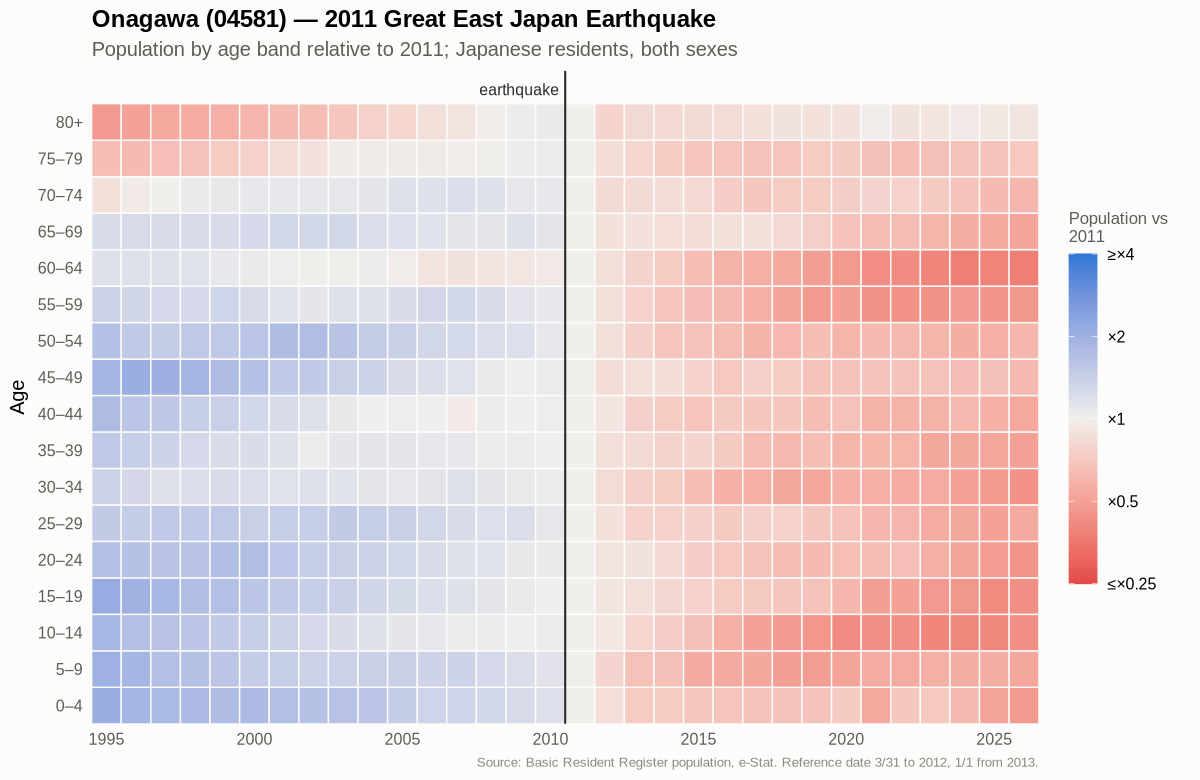

In [5]:
show_save(plot_town("04581"), "01_onagawa")

## Figure 2: Mashiki, 2016 Kumamoto Earthquake

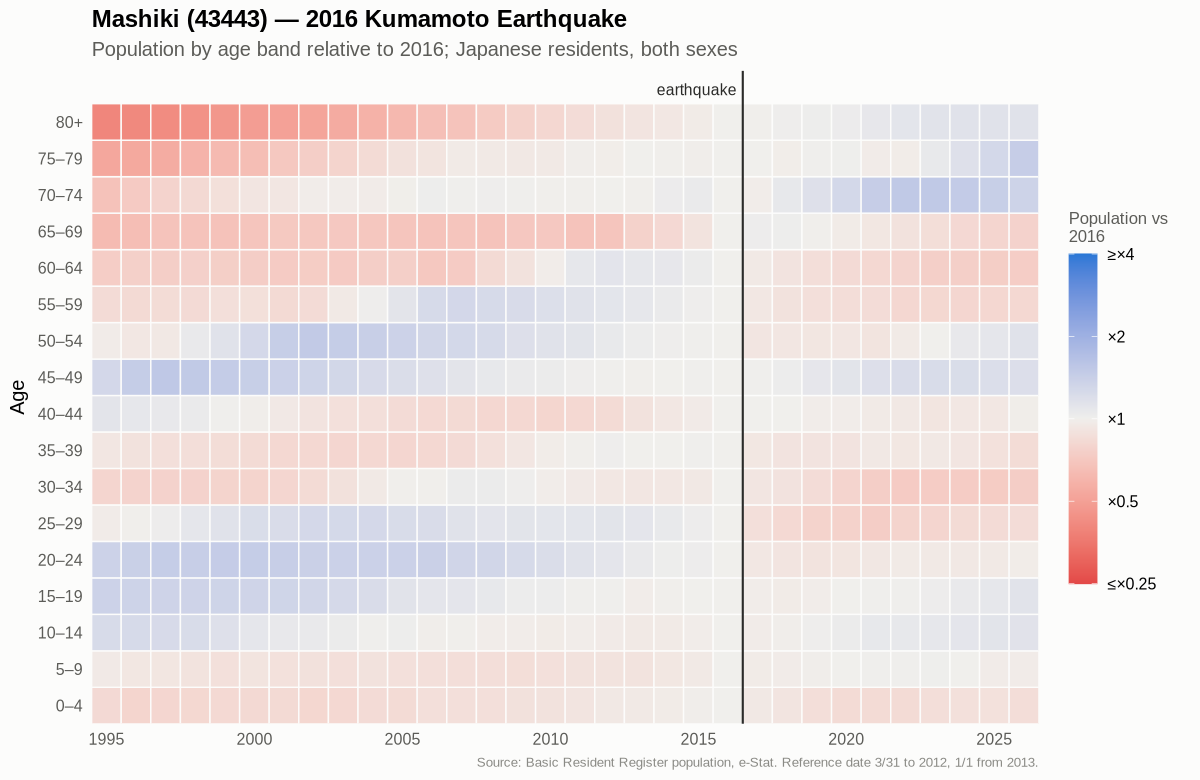

In [6]:
show_save(plot_town("43443"), "02_mashiki")

## Figure 3: Suzu, 2024 Noto Peninsula Earthquake

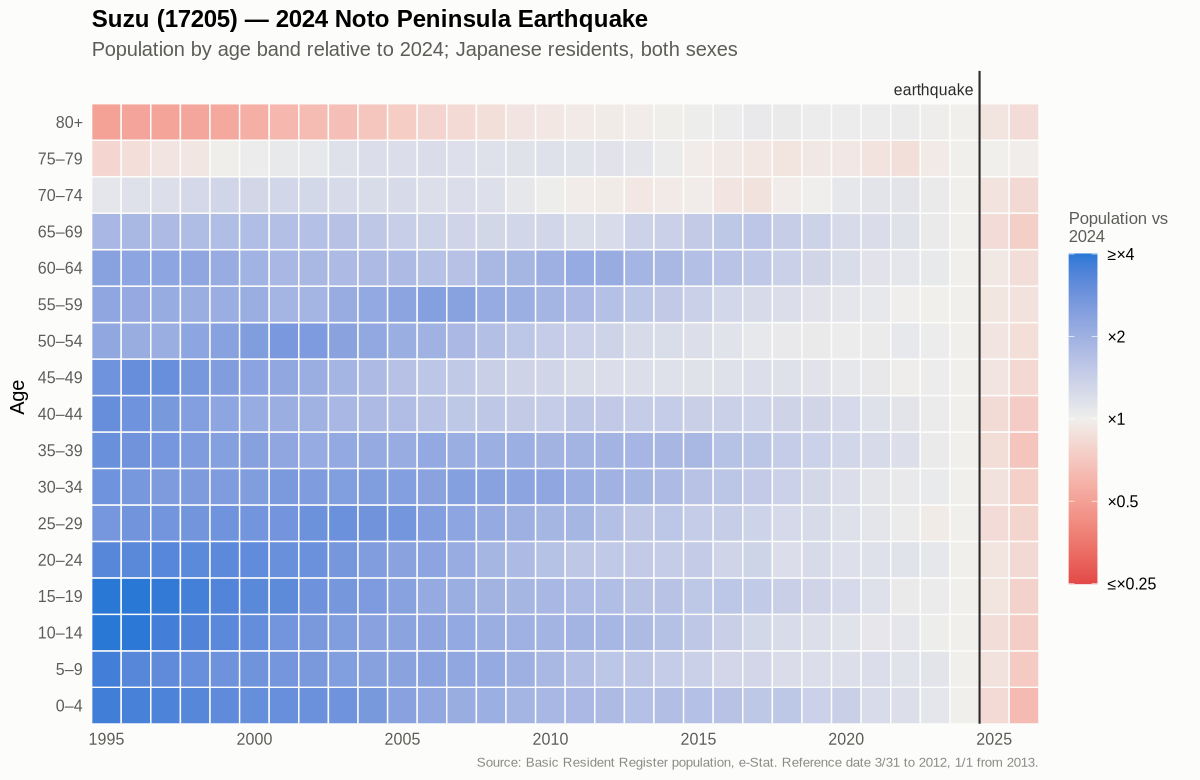

In [7]:
show_save(plot_town("17205"), "03_suzu")

## Maps

Two sets of maps, one map per disaster in each set. Each map covers the affected prefectures **and every prefecture bordering them**; for 熊本 that means the whole of Kyushu.

- **Population (figures 4–6):** total population in the disaster year.
- **Damage (figures 7–9):** 全壊棟数, the number of fully destroyed buildings.

Common to both sets:
- **Affected** comes from `dt/analysis_original_data.xlsx`. Affected municipalities are those listed in `1_市町村一覧` for the map's disaster (2011: 東日本 + 福島), and affected prefectures are their prefectures, with names in bold. Only the neighbouring prefectures are listed in code.
- **Boundaries:** 国土数値情報 行政区域 (N03), 2025-01-01, fetched and cached by `src/fetch_n03.R`. Wards are merged into their city, holes are dropped and long boundaries thinned. Far-off islands are cropped; the caption says so.
- The municipality from each heatmap above is outlined and labelled.

In [8]:
library(ggnewscale)

poly_cache <- file.path(root, "dt/raw/n03/n03_2025_polygons.qs2")
if (!file.exists(poly_cache)) source(file.path(root, "src/fetch_n03.R"))
polys <- qs_read(poly_cache)

pref_names <- c("02" = "Aomori", "03" = "Iwate", "04" = "Miyagi", "05" = "Akita",
                "06" = "Yamagata", "07" = "Fukushima", "08" = "Ibaraki",
                "09" = "Tochigi", "10" = "Gunma", "15" = "Niigata",
                "16" = "Toyama", "17" = "Ishikawa", "18" = "Fukui", "21" = "Gifu",
                "40" = "Fukuoka", "41" = "Saga", "42" = "Nagasaki",
                "43" = "Kumamoto", "44" = "Oita", "45" = "Miyazaki",
                "46" = "Kagoshima")

xlsx <- file.path(root, "dt/analysis_original_data.xlsx")
study <- readxl::read_excel(xlsx, sheet = "1_市町村一覧", col_types = "text") |>
  transmute(code = 市町村コード, disaster = 災害, pref_code = substr(市町村コード, 1, 2))

# Former codes -> current code used by the 2025 boundaries
merge_map <- readr::read_csv(file.path(root, "src/merge_map.csv"),
                             col_types = readr::cols(.default = "c"))
to_current <- function(df) {
  df |>
    left_join(select(merge_map, former, survivor), by = c("code" = "former")) |>
    mutate(code = coalesce(survivor, code)) |>
    select(-survivor)
}

# xlim / ylim crop the frame (NULL = everything). Cropped: Tsushima, the
# Satsunan islands south of Kyushu, and Ishikawa's 舳倉島 / 七ツ島.
map_sets <- tribble(
  ~map_id,    ~disasters,            ~neighbours,
  ~base_year, ~xlim,               ~ylim,            ~region,                       ~event,
  "tohoku",   c("東日本", "福島"),   c("02", "05", "06", "08", "09", "10", "15"),
  2011,       NULL,                NULL,             "Tohoku and surroundings",     "2011 Great East Japan Earthquake",
  "kumamoto", "熊本",                c("40", "41", "42", "44", "45", "46"),
  2016,       c(128.55, 132.15),   c(30.95, 34.0),   "Kyushu",                      "2016 Kumamoto Earthquake",
  "noto",     "能登",                c("16", "18", "21"),
  2024,       NULL,                c(35.1, 37.56),   "Ishikawa and surroundings",   "2024 Noto Peninsula Earthquake"
) |>
  rowwise() |>
  mutate(
    affected_codes = list(study$code[study$disaster %in% disasters]),
    affected = list(sort(unique(study$pref_code[study$disaster %in% disasters]))),
    prefs = list(union(affected, neighbours))
  ) |>
  ungroup()
map_sets |>
  transmute(map_id, base_year,
            disasters = sapply(disasters, paste, collapse = ", "),
            listed_municipalities = lengths(affected_codes),
            affected_prefectures = sapply(affected, paste, collapse = ", "),
            neighbours = sapply(neighbours, paste, collapse = ", "))

map_id,base_year,disasters,listed_municipalities,affected_prefectures,neighbours
<chr>,<dbl>,<chr>,<int>,<chr>,<chr>
tohoku,2011,"東日本, 福島",123,"03, 04, 07","02, 05, 06, 08, 09, 10, 15"
kumamoto,2016,熊本,45,43,"40, 41, 42, 44, 45, 46"
noto,2024,能登,19,17,"16, 18, 21"


In [9]:
# Shared pieces for every map: polygons for the frame (crop applied), prefecture
# labels, the outlined heatmap municipality, and the common theme.
map_frame <- function(id) {
  m <- map_sets |> filter(map_id == id)
  d <- polys |>
    filter(pref_code %in% m$prefs[[1]]) |>
    mutate(affected = code %in% m$affected_codes[[1]])
  xlim <- m$xlim[[1]]
  ylim <- m$ylim[[1]]
  in_frame <- function(v, lim) is.null(lim) || (max(v) >= lim[1] & min(v) <= lim[2])
  # Drop parts lying wholly outside the frame (clip is off for labels)
  d <- d |>
    group_by(part) |>
    filter(in_frame(x, xlim), in_frame(y, ylim)) |>
    ungroup()
  pref_lab <- d |>
    group_by(pref_code) |>
    summarise(x = mean(range(x)), y = mean(range(y)), .groups = "drop") |>
    mutate(label = pref_names[pref_code],
           affected = pref_code %in% m$affected[[1]])
  hl_code <- towns$code[towns$base_year == m$base_year]
  hl <- d |> filter(code %in% hl_code)
  lab <- hl |>
    summarise(x = max(x) + 0.02 * diff(range(d$x)), y = mean(range(y))) |>
    mutate(label = towns$name[towns$code %in% hl_code])
  list(m = m, d = d, pref_lab = pref_lab, hl = hl, lab = lab,
       xlim = xlim, ylim = ylim, cropped = !is.null(xlim) || !is.null(ylim))
}

map_layers <- function(f) {
  list(
    geom_polygon(data = f$hl, aes(x, y, group = part), fill = NA,
                 colour = "#2b2b29", linewidth = 0.7, inherit.aes = FALSE),
    geom_label(data = f$pref_lab, aes(x, y, label = toupper(label),
                                      fontface = ifelse(affected, "bold", "plain")),
               inherit.aes = FALSE, size = 3, colour = "#2b2b29",
               fill = alpha(surface, 0.85), linewidth = 0,
               label.padding = unit(0.12, "lines")),
    geom_label(data = f$lab, aes(x, y, label = label), inherit.aes = FALSE,
               hjust = 0, size = 3.6, fontface = "bold", fill = surface,
               colour = "#2b2b29", linewidth = 0,
               label.padding = unit(0.15, "lines")),
    coord_quickmap(xlim = f$xlim, ylim = f$ylim, expand = FALSE, clip = "off"),
    theme_void(base_size = 12),
    theme(
      plot.background = element_rect(fill = surface, colour = NA),
      plot.title = element_text(face = "bold", margin = margin(b = 4)),
      plot.subtitle = element_text(colour = "#5c5c58", margin = margin(b = 8)),
      plot.caption = element_text(colour = "#8a8a85", size = 8, hjust = 0,
                                  margin = margin(t = 8)),
      plot.caption.position = "plot",
      plot.title.position = "plot",
      legend.title = element_text(size = 10, colour = "#5c5c58"),
      legend.text = element_text(colour = "#5c5c58"),
      legend.spacing.y = unit(0.4, "cm"),
      legend.box.spacing = unit(1.4, "cm"),
      plot.margin = margin(12, 12, 12, 12)
    )
  )
}
boundary_note <- function(f) {
  paste0("Boundaries: MLIT National Land Numerical Information N03, 2025.",
         if (f$cropped) " Far-off islands outside the frame are not shown." else "")
}

### Population in the disaster year

Each municipality is coloured by its total population (Japanese residents, both sexes) in the disaster year, as for the heatmaps: 2011, 2016 and 2024.

- **Population data:** `dt/jumin_total_all_municipalities.qs2`, which holds every municipality in Japan, built by `src/build_jumin_age.R`.
- **Colour:** affected (listed) municipalities in an orange scale, all other municipalities in a blue scale. Each runs light to dark on the same log scale, with its own legend. Grey means no population data for that year.
- **Unlisted municipalities:** those inside affected prefectures (仙台市, 檜枝岐村, 浪江町, 飯舘村) count as "other".

In [10]:
# Total population for every municipality (japanese basis, both sexes, city
# rows rather than wards), former codes summed into the current code
total_pop <- qs_read(file.path(root, "dt/jumin_total_all_municipalities.qs2")) |>
  filter(basis == "japanese", sex == "計", level == "municipality") |>
  to_current() |>
  group_by(code, year) |>
  summarise(pop = sum(pop), .groups = "drop")

# Match check: study municipalities without a polygon, and mapped codes
# without population in the map's year (these show grey)
map_codes <- polys |> filter(!is.na(code)) |> distinct(code, pref_code)
no_pop <- map_sets |>
  rowwise() |>
  reframe(map_id, base_year, code = map_codes$code[map_codes$pref_code %in% prefs]) |>
  anti_join(total_pop, by = c("code", "base_year" = "year"))
no_poly <- anti_join(study, map_codes, by = "code")
tibble(
  check = c("study municipalities", "study municipalities with no polygon",
            "mapped codes with no population (grey)"),
  n = c(nrow(study), nrow(no_poly), nrow(no_pop)),
  codes = c("", paste(no_poly$code, collapse = ", "),
            paste(paste0(no_pop$code, " (", no_pop$map_id, ")"), collapse = ", "))
)

check,n,codes
<chr>,<int>,<chr>
study municipalities,187,
study municipalities with no polygon,0,
mapped codes with no population (grey),2,"40000 (kumamoto), 46000 (kumamoto)"


In [11]:
# Affected: orange scale; others: blue scale. Both start one step above the
# palest tint, where blue vs orange still separates for colour-blind readers
# (dataviz validator: dE 11.7 CVD, 15.9 normal; the palest pair was 5.9 / 7.8).
blue_ramp <- c("#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab",
               "#104281", "#0d366b")
orange_ramp <- colorRampPalette(c("#fdc0a6", "#eb6834", "#7a2a0f"),
                                space = "Lab")(7)
pop_breaks <- c(1e3, 3e3, 1e4, 3e4, 1e5, 3e5, 1e6)
pop_labels <- c("≤1,000", "3,000", "10,000", "30,000", "100,000",
                "300,000", "≥1,000,000")
pop_fill <- function(colours, name, order) {
  scale_fill_gradientn(
    colours = colours, trans = "log10",
    limits = range(pop_breaks), oob = scales::squish,
    breaks = pop_breaks, labels = pop_labels,
    na.value = "#d9d8d4", name = name,
    guide = guide_colourbar(order = order)
  )
}

plot_pop_map <- function(id) {
  f <- map_frame(id)
  d <- f$d |> left_join(total_pop |> filter(year == f$m$base_year), by = "code")
  ggplot(d, aes(x, y, group = part)) +
    geom_polygon(data = filter(d, affected), aes(fill = pop),
                 colour = surface, linewidth = 0.15) +
    pop_fill(orange_ramp, "Affected\n(listed in\nanalysis data)", 1) +
    new_scale_fill() +
    geom_polygon(data = filter(d, !affected), aes(fill = pop),
                 colour = surface, linewidth = 0.15) +
    pop_fill(blue_ramp, "Other\nmunicipalities", 2) +
    map_layers(f) +
    theme(legend.key.height = unit(1.1, "cm")) +
    labs(
      title = paste0(f$m$region, ": population in ", f$m$base_year),
      subtitle = paste0("Total population by municipality; Japanese residents, both sexes.\n",
                        "Orange: listed in the analysis data (prefecture in bold). Blue: other municipalities."),
      caption = paste0("Population: Basic Resident Register, e-Stat (", f$m$base_year,
                       "). Grey: no data.\n", boundary_note(f)),
      x = NULL, y = NULL
    )
}

## Figure 4: Tohoku and surroundings, population in 2011

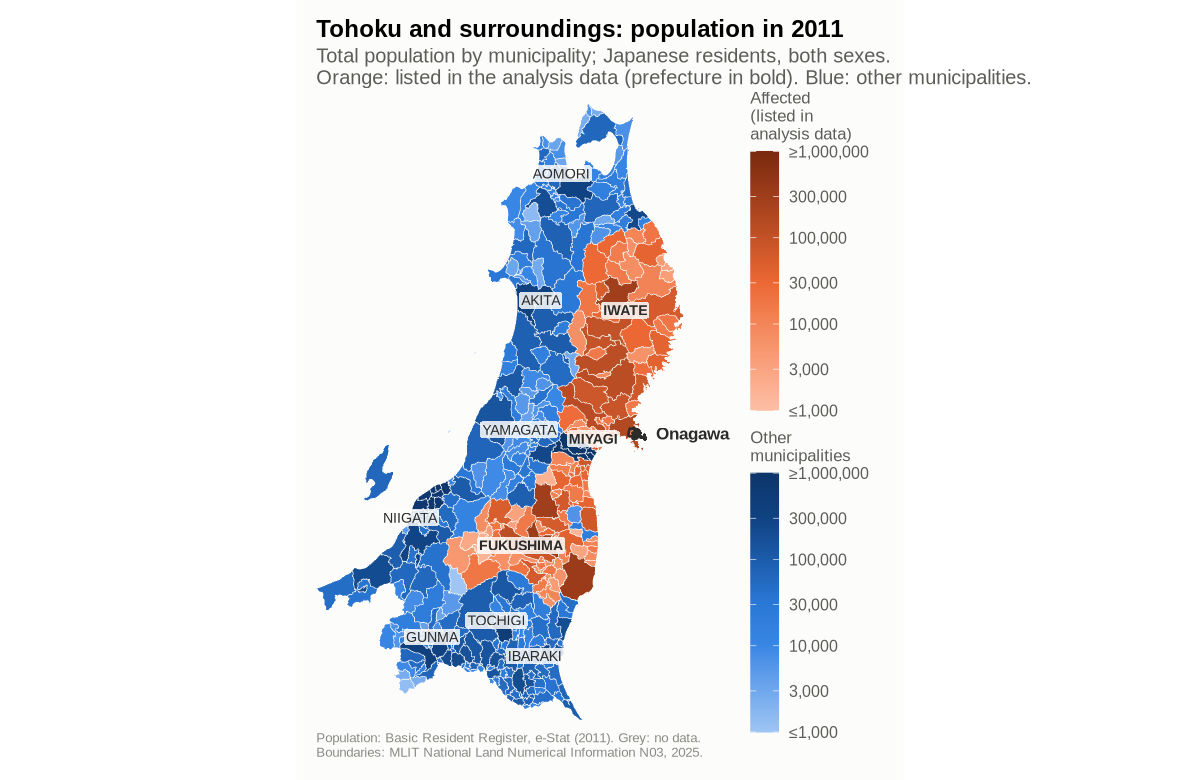

In [12]:
show_save(plot_pop_map("tohoku"), "04_map_tohoku", width = 8.5, height = 11)

## Figure 5: Kyushu, population in 2016

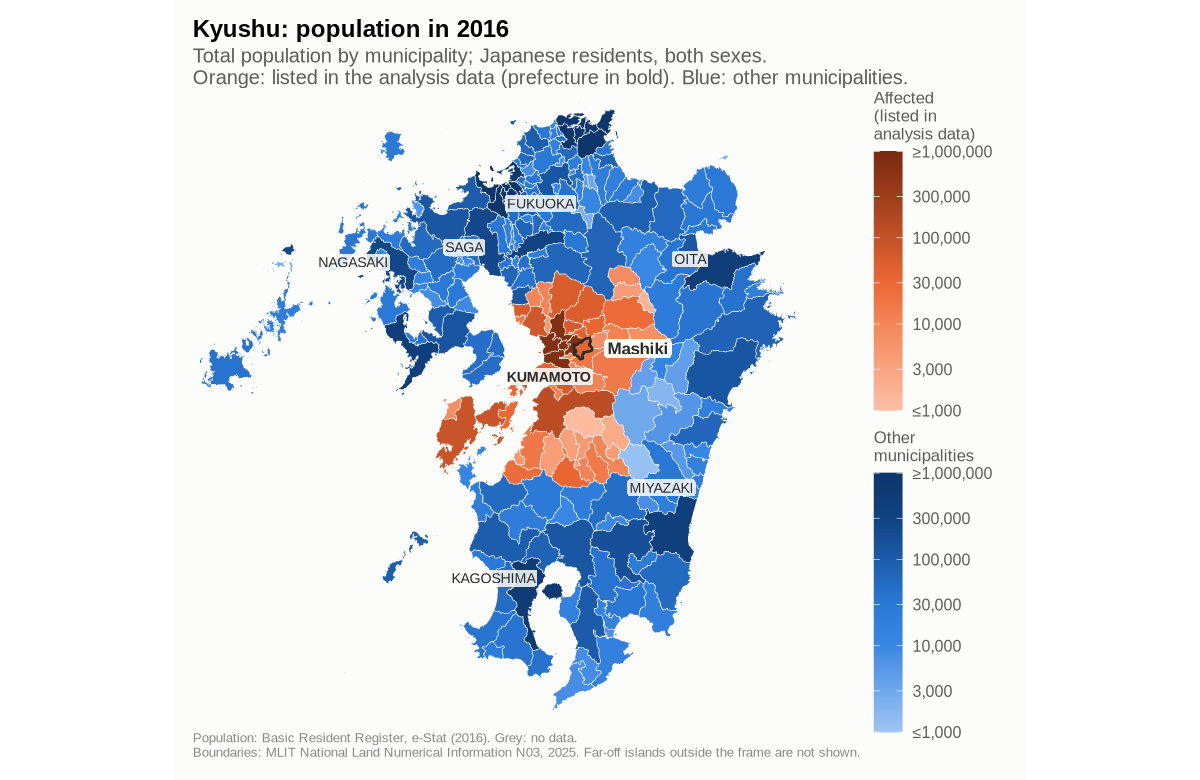

In [13]:
show_save(plot_pop_map("kumamoto"), "05_map_kumamoto", width = 9, height = 9.5)

## Figure 6: Ishikawa and surroundings, population in 2024

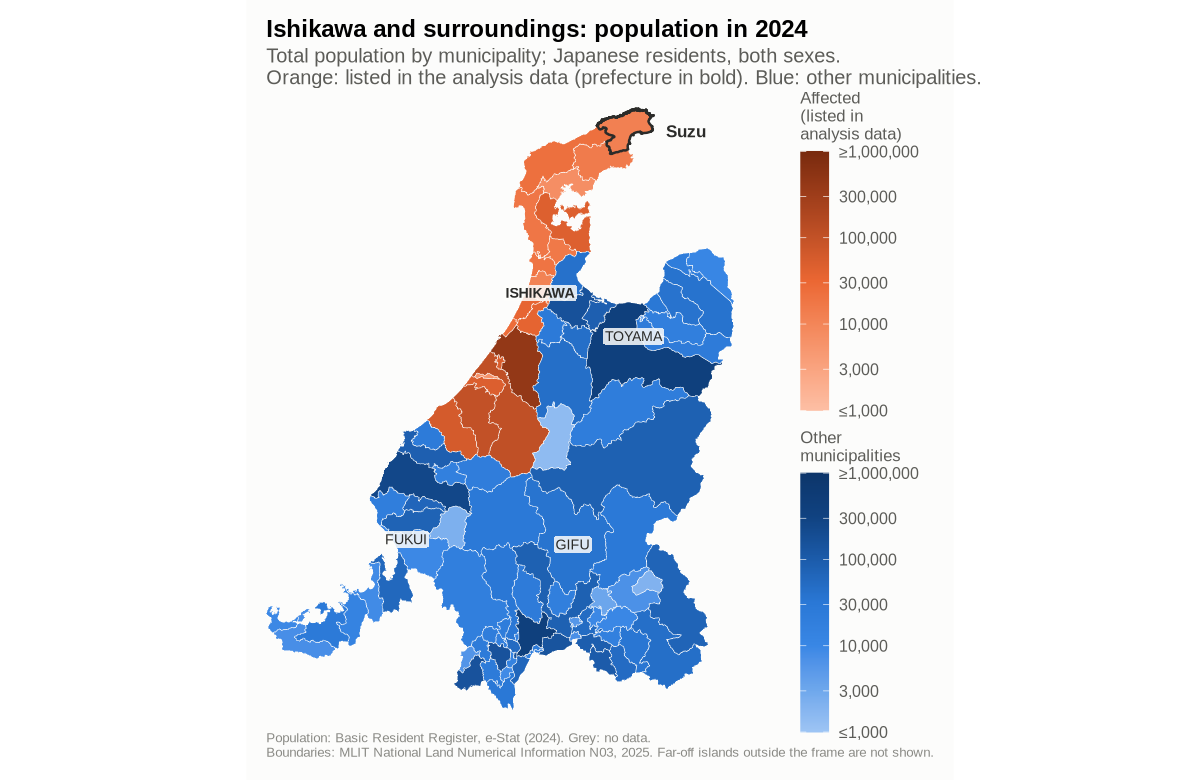

In [14]:
show_save(plot_pop_map("noto"), "06_map_noto", width = 9, height = 9.5)

### 全壊棟数 (fully destroyed buildings)

Each municipality is coloured by its number of fully destroyed buildings (全壊棟数).

- **Damage data:** `dt/analysis_original_data.xlsx`, sheet `8_被害データ`, from 消防白書 H26 附属資料1 (Iwate, Miyagi, Fukushima), 熊本県 第289報 and 石川県 第204報. It covers the 187 study municipalities plus 仙台市, 浪江町, 飯舘村 and 檜枝岐村. Municipalities without a row in the source count as 0, as in the protocol.
- **Colour:** one orange scale in bins (0 / 1–9 / 10–99 / 100–999 / 1,000–9,999 / ≥10,000). 0 is the palest shade. **Grey** means no damage data: the surrounding prefectures, which are outside the study area.

In [15]:
damage <- readxl::read_excel(xlsx, sheet = "8_被害データ",
                             col_types = c("text", "text", "text", "numeric",
                                           "numeric", "logical", "text")) |>
  to_current() |>
  group_by(code) |>
  summarise(zen = sum(zen), .groups = "drop")

# Match check: damage rows without a polygon, and municipalities in the
# affected prefectures without a damage row (none expected)
aff_codes <- map_codes |> filter(pref_code %in% unlist(map_sets$affected))
tibble(
  check = c("damage rows (sheet 8)", "damage rows with no polygon",
            "municipalities in affected prefectures with no damage row"),
  n = c(nrow(damage), nrow(anti_join(damage, map_codes, by = "code")),
        nrow(anti_join(aff_codes, damage, by = "code"))),
  codes = c("", paste(anti_join(damage, map_codes, by = "code")$code, collapse = ", "),
            paste(anti_join(aff_codes, damage, by = "code")$code, collapse = ", "))
)

check,n,codes
<chr>,<int>,<chr>
damage rows (sheet 8),191,
damage rows with no polygon,0,
municipalities in affected prefectures with no damage row,0,


In [16]:
# Bins for 全壊棟数; one orange scale, light to dark (0 = palest)
zen_bins <- c("0", "1–9", "10–99", "100–999", "1,000–9,999", "≥10,000")
zen_cols <- setNames(colorRampPalette(c("#fde3d6", "#eb6834", "#7a2a0f"),
                                      space = "Lab")(length(zen_bins)), zen_bins)
bin_zen <- function(z) {
  factor(cut(z, c(-Inf, 0, 9, 99, 999, 9999, Inf), labels = zen_bins),
         levels = zen_bins)
}

# Figure text must stay ASCII/English: no Japanese font in the container
damage_source <- c(
  tohoku   = "FDMA White Paper on Fire Service 2014, annex 1",
  kumamoto = "Kumamoto Prefecture disaster HQ, report 289",
  noto     = "Ishikawa Prefecture disaster HQ, report 204 (2025-05-13)"
)

plot_damage_map <- function(id) {
  f <- map_frame(id)
  d <- f$d |> left_join(damage, by = "code") |> mutate(zen_bin = bin_zen(zen))
  ggplot(d, aes(x, y, group = part)) +
    geom_polygon(aes(fill = zen_bin), colour = surface, linewidth = 0.15,
                 show.legend = TRUE) +
    scale_fill_manual(values = zen_cols, drop = FALSE, na.value = "#d9d8d4",
                      na.translate = TRUE,
                      labels = function(x) ifelse(is.na(x), "No data\n(outside study area)", x),
                      name = "Fully destroyed\nbuildings") +
    map_layers(f) +
    theme(legend.key.size = unit(0.6, "cm")) +
    labs(
      title = paste0(f$m$event, ": fully destroyed buildings"),
      subtitle = paste0("Number of fully destroyed buildings by municipality.\n",
                        "Affected prefectures in bold; surrounding prefectures in grey (no damage data)."),
      caption = paste0("Damage: ", damage_source[[id]],
                       " (sheet 8 of the analysis data).\n", boundary_note(f)),
      x = NULL, y = NULL
    )
}

## Figure 7: 2011 Great East Japan Earthquake, fully destroyed buildings

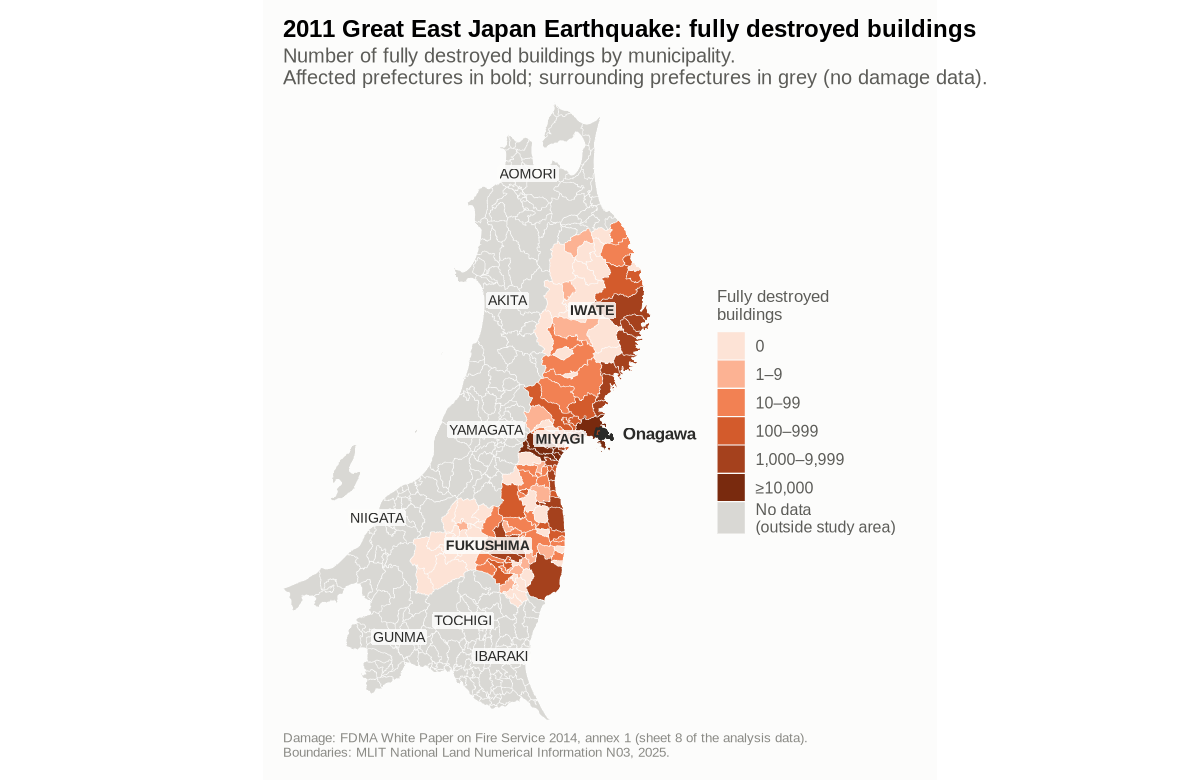

In [17]:
show_save(plot_damage_map("tohoku"), "07_map_damage_tohoku", width = 8.5, height = 11)

## Figure 8: 2016 Kumamoto Earthquake, fully destroyed buildings

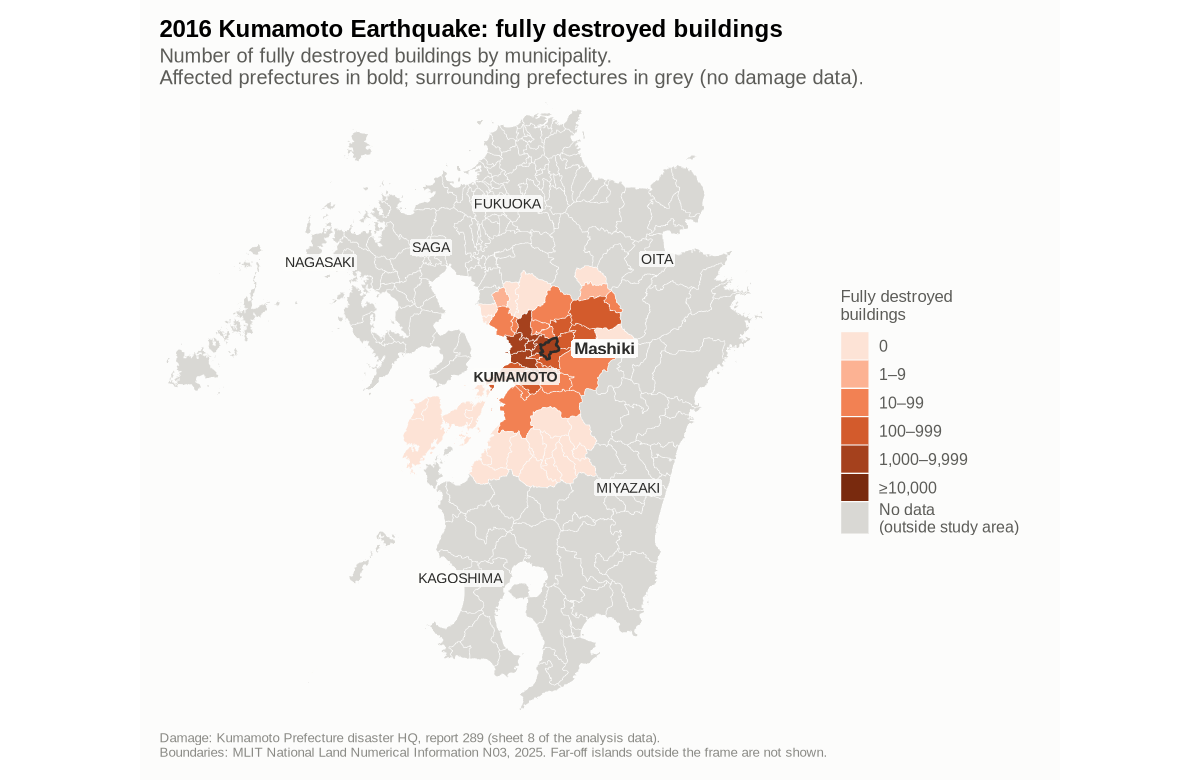

In [18]:
show_save(plot_damage_map("kumamoto"), "08_map_damage_kumamoto", width = 9, height = 9.5)

## Figure 9: 2024 Noto Peninsula Earthquake, fully destroyed buildings

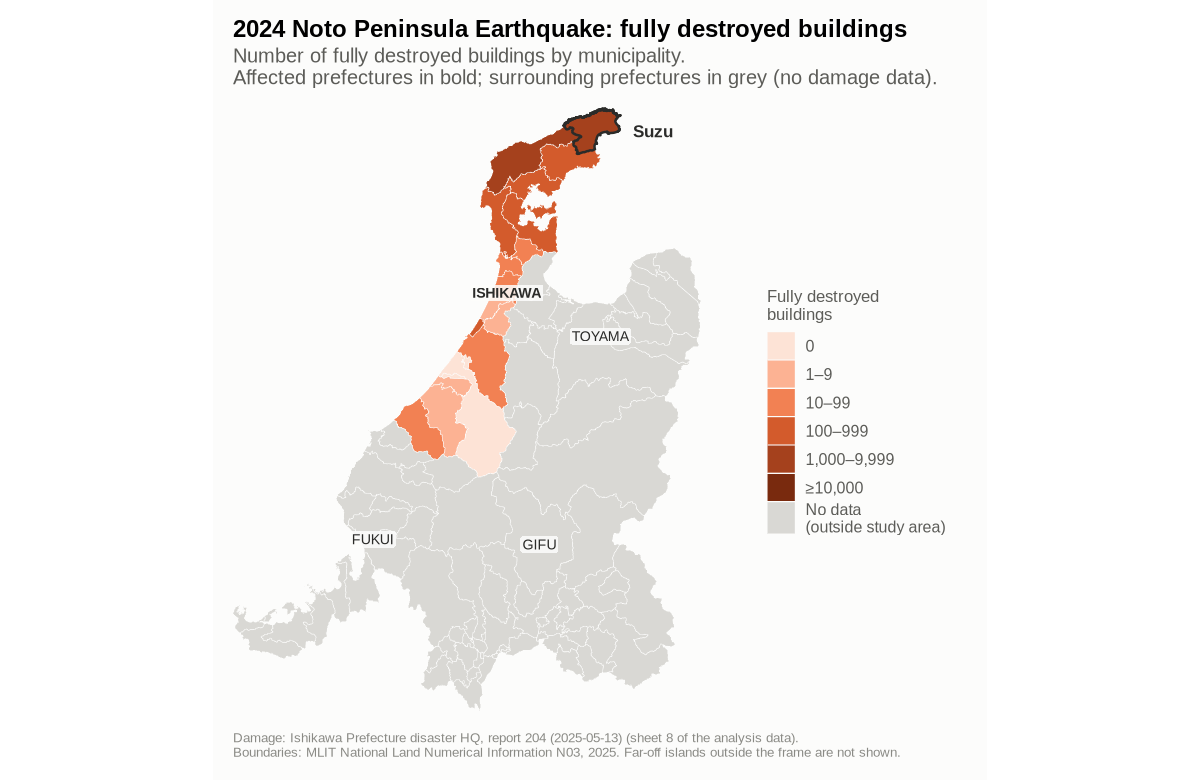

In [19]:
show_save(plot_damage_map("noto"), "09_map_damage_noto", width = 9, height = 9.5)

## Population trends around each disaster (±5 years), by municipality

One line per municipality, from 5 years before to 5 years after each disaster year. Noto only runs to 2026, the latest data.

- **Affected (orange):** the municipalities listed in `1_市町村一覧` for the disaster (2011: 東日本 + 福島; 熊本; 能登). Former codes are joined via `src/merge_map.csv`.
- **Non-affected (blue):** every other municipality in the same region as the maps: unlisted municipalities in the affected prefectures (e.g. 仙台市) plus the neighbouring prefectures.
  - Only municipalities with a value in every year of the window are kept.
  - Non-affected municipalities with a merger jump inside the window (any year-on-year change above +3% or below −25%, the protocol's candidate rule) are dropped. The table below counts them.
- **Rows:**
  - top: total population on a log scale, which shows size;
  - bottom: each municipality indexed to the disaster year (= 100), which shows the change. The bold line is the median.
- **Highlight:** the municipality from each heatmap is drawn in dark ink and labelled.
- **Data:** `dt/jumin_total_all_municipalities.qs2`, Japanese residents, both sexes, `level == "municipality"`.
- **Reference dates:** 3/31 up to 2012 and 1/1 from 2013, so the 2012→2013 step covers only 9 months.

In [20]:
region_pop <- qs_read(file.path(root, "dt/jumin_total_all_municipalities.qs2")) |>
  filter(basis == "japanese", sex == "計", level == "municipality") |>
  to_current() |>
  group_by(code, year) |>
  summarise(pop = sum(pop), .groups = "drop") |>
  mutate(pref_code = substr(code, 1, 2))
last_year <- max(region_pop$year)

trend_muni <- map_sets |>
  rowwise() |>
  reframe({
    yrs <- (base_year - 5):min(base_year + 5, last_year)
    region_pop |>
      filter(pref_code %in% prefs, year %in% yrs) |>
      mutate(map_id = map_id, base_year = base_year, n_years = length(yrs),
             affected = code %in% affected_codes)
  }) |>
  group_by(map_id, code) |>
  arrange(year, .by_group = TRUE) |>
  mutate(
    complete = n() == n_years,
    yoy = pop / lag(pop) - 1,
    merger_jump = any(yoy > 0.03 | yoy < -0.25, na.rm = TRUE),
    index = 100 * pop / pop[year == base_year][1]
  ) |>
  ungroup()

# Which municipalities are kept per map and area
trend_muni |>
  distinct(map_id, code, affected, complete, merger_jump) |>
  group_by(map_id, area = ifelse(affected, "affected", "non-affected")) |>
  summarise(municipalities = n(),
            dropped_incomplete = sum(!complete),
            dropped_merger_jump = sum(complete & merger_jump & !affected),
            affected_with_jump_kept = sum(complete & merger_jump & affected),
            plotted = sum(complete & (affected | !merger_jump)),
            .groups = "drop")

map_id,area,municipalities,dropped_incomplete,dropped_merger_jump,affected_with_jump_kept,plotted
<chr>,<chr>,<int>,<int>,<int>,<int>,<int>
kumamoto,affected,45,0,0,0,45
kumamoto,non-affected,188,0,3,0,185
noto,affected,19,0,0,0,19
noto,non-affected,74,0,0,0,74
tohoku,affected,123,0,0,0,123
tohoku,non-affected,256,19,10,0,227


In [21]:
area_cols <- c(affected = "#eb6834", non_affected = "#2a78d6")

# One y label function for both rows: the top row holds log10(population)
# (values < 10), the bottom row the index (values around 100).
pop_ticks <- c(100, 300, 1e3, 3e3, 1e4, 3e4, 1e5, 3e5, 1e6, 3e6)
y_breaks <- function(lim) {
  if (max(lim) < 10) log10(pop_ticks)[log10(pop_ticks) >= lim[1] & log10(pop_ticks) <= lim[2]]
  else scales::breaks_extended()(lim)
}
y_labels <- function(v) {
  ifelse(v < 10, scales::label_comma()(round(10^v)), as.character(v))
}

plot_trend <- function(id) {
  m <- map_sets |> filter(map_id == id)
  ev <- towns$event_x[towns$base_year == m$base_year]
  hl_code <- towns$code[towns$base_year == m$base_year]
  hl_name <- towns$name[towns$base_year == m$base_year]
  d <- trend_muni |>
    filter(map_id == id, complete, affected | !merger_jump) |>
    mutate(area = ifelse(affected, "affected", "non_affected"))
  n_area <- d |> distinct(area, code) |> count(area)
  col_lab <- c(
    affected = sprintf("Affected: listed municipalities (n = %d)",
                       n_area$n[n_area$area == "affected"]),
    non_affected = sprintf("Non-affected: rest of the region (n = %d)",
                           n_area$n[n_area$area == "non_affected"])
  )
  row_lab <- c(pop = "Total population (log scale)",
               index = paste0("Index (", m$base_year, " = 100)"))
  long <- bind_rows(
    d |> transmute(code, year, area, measure = "pop", value = log10(pop)),
    d |> transmute(code, year, area, measure = "index", value = index)
  ) |>
    mutate(area_f = factor(col_lab[area], levels = col_lab),
           measure_f = factor(row_lab[measure], levels = row_lab))
  med <- long |>
    filter(measure == "index") |>
    group_by(area, area_f, measure_f, year) |>
    summarise(value = median(value), .groups = "drop")
  hl <- long |> filter(code == hl_code)
  hl_end <- hl |> filter(year == max(year))
  ref100 <- data.frame(measure_f = factor(row_lab[["index"]], levels = row_lab), y = 100)

  ggplot(long, aes(year, value, colour = area)) +
    geom_vline(xintercept = ev, colour = "#8a8a85", linewidth = 0.5, linetype = "22") +
    geom_hline(data = ref100, aes(yintercept = y), colour = "#8a8a85", linewidth = 0.4) +
    geom_line(aes(group = code), linewidth = 0.3, alpha = 0.35) +
    geom_line(data = med, aes(group = area), linewidth = 1.4) +
    geom_line(data = hl, aes(group = code), colour = "#2b2b29", linewidth = 1) +
    geom_text(data = hl_end, aes(label = hl_name), colour = "#2b2b29",
              hjust = -0.15, size = 3.3, fontface = "bold") +
    facet_grid(measure_f ~ area_f, scales = "free_y", switch = "y") +
    scale_colour_manual(values = area_cols, guide = "none") +
    scale_x_continuous(breaks = seq(m$base_year - 5, m$base_year + 5, by = 1),
                       labels = function(x) ifelse((x - m$base_year) %% 5 == 0, x, ""),
                       expand = expansion(mult = c(0.02, 0.14))) +
    scale_y_continuous(breaks = y_breaks, labels = y_labels) +
    coord_cartesian(clip = "off") +
    labs(
      title = paste0(m$event, ": population by municipality, ", m$base_year - 5, "–",
                     min(m$base_year + 5, last_year)),
      subtitle = paste0(m$region, ". One thin line per municipality; bold line = median; ",
                        "dark line = ", hl_name, ". Dashed line: the earthquake."),
      caption = paste0(
        "Population: Basic Resident Register, e-Stat; Japanese residents, both sexes.",
        if (m$base_year - 5 <= 2012 && m$base_year + 5 >= 2013)
          " Reference date 3/31 to 2012, 1/1 from 2013 (the 2012→2013 step covers 9 months)."
        else " Reference date 1 January.",
        "\nNon-affected municipalities with a merger jump in the window are excluded (see table above).",
        if (m$base_year + 5 > last_year) paste0(" Data end in ", last_year, ".") else ""),
      x = NULL, y = NULL
    ) +
    theme_minimal(base_size = 12) +
    theme(
      plot.background = element_rect(fill = surface, colour = NA),
      panel.grid.minor = element_blank(),
      panel.grid.major.x = element_blank(),
      panel.grid.major.y = element_line(colour = "#e6e5e1", linewidth = 0.4),
      panel.spacing = unit(0.8, "cm"),
      strip.text.x = element_text(face = "bold", hjust = 0, colour = "#2b2b29"),
      strip.text.y.left = element_text(angle = 90, colour = "#5c5c58"),
      strip.placement = "outside",
      plot.title = element_text(face = "bold"),
      plot.subtitle = element_text(colour = "#5c5c58", size = 10.5),
      plot.caption = element_text(colour = "#8a8a85", size = 8, hjust = 0),
      plot.title.position = "plot",
      plot.caption.position = "plot",
      axis.text = element_text(colour = "#5c5c58")
    )
}

## Figure 10: 2011 Great East Japan Earthquake, population by municipality 2006–2016

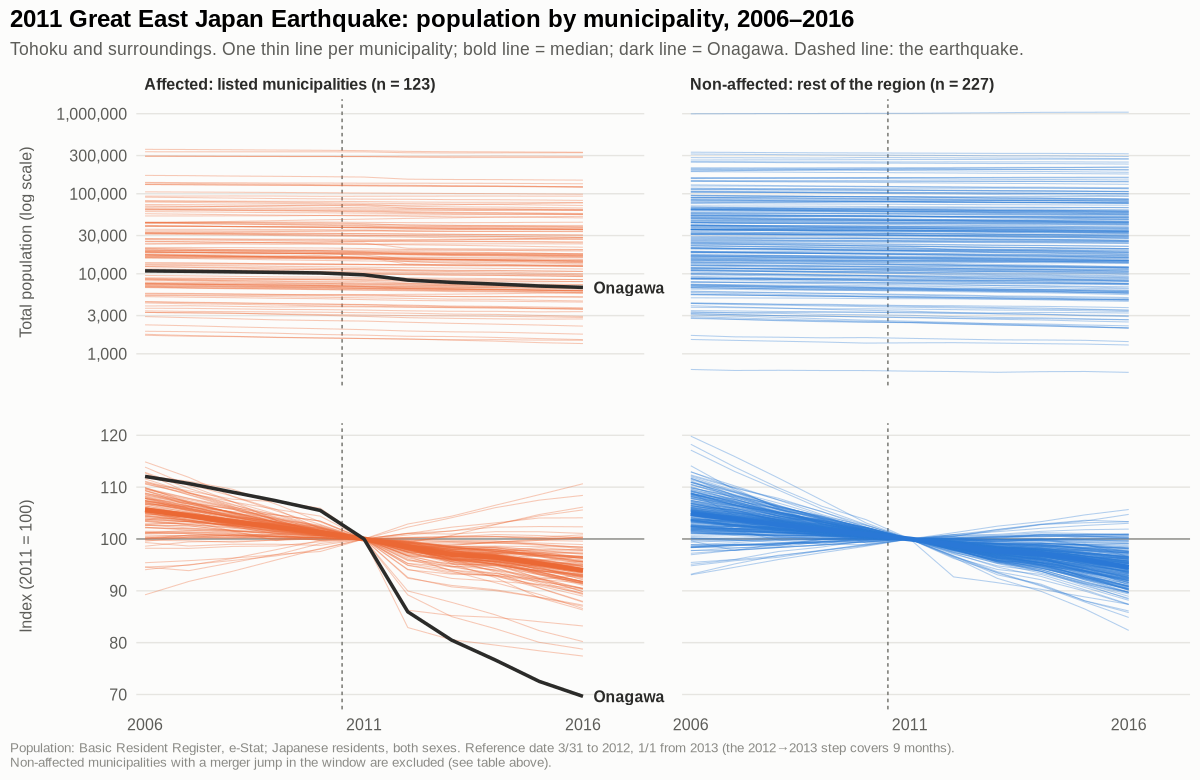

In [22]:
show_save(plot_trend("tohoku"), "10_trend_tohoku", width = 12, height = 9)

## Figure 11: 2016 Kumamoto Earthquake, population by municipality 2011–2021

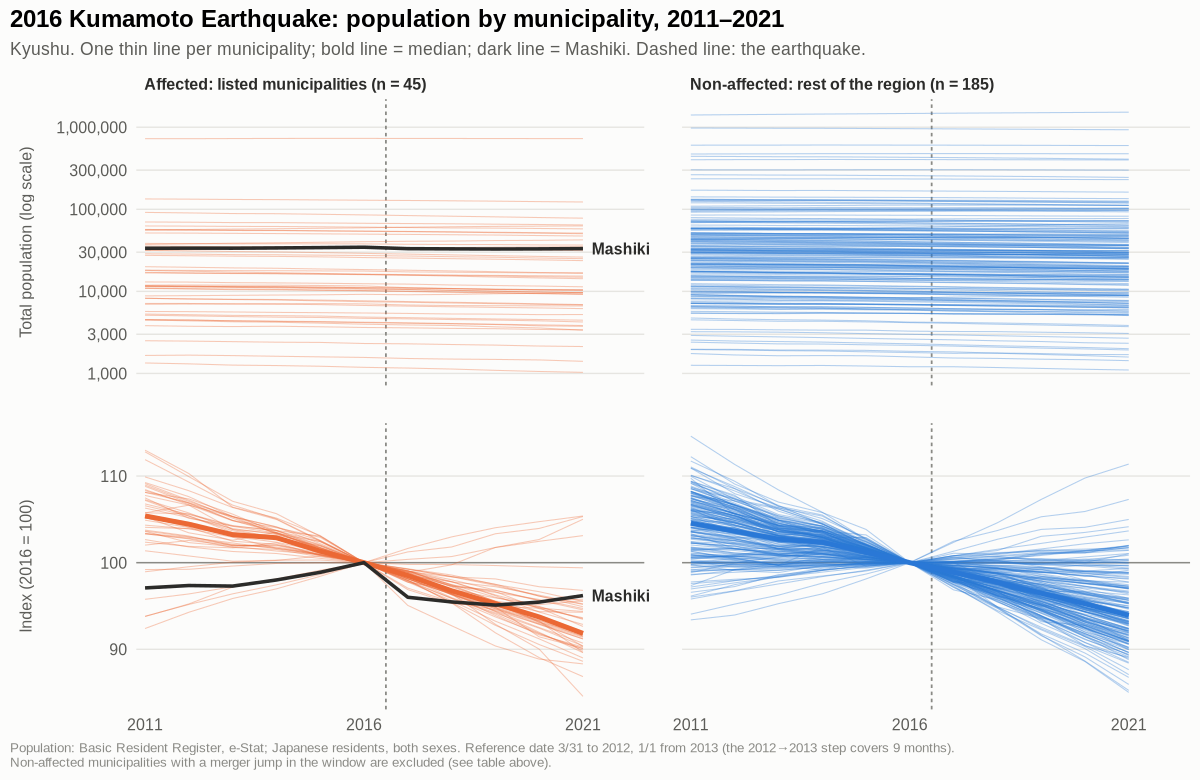

In [23]:
show_save(plot_trend("kumamoto"), "11_trend_kumamoto", width = 12, height = 9)

## Figure 12: 2024 Noto Peninsula Earthquake, population by municipality 2019–2026

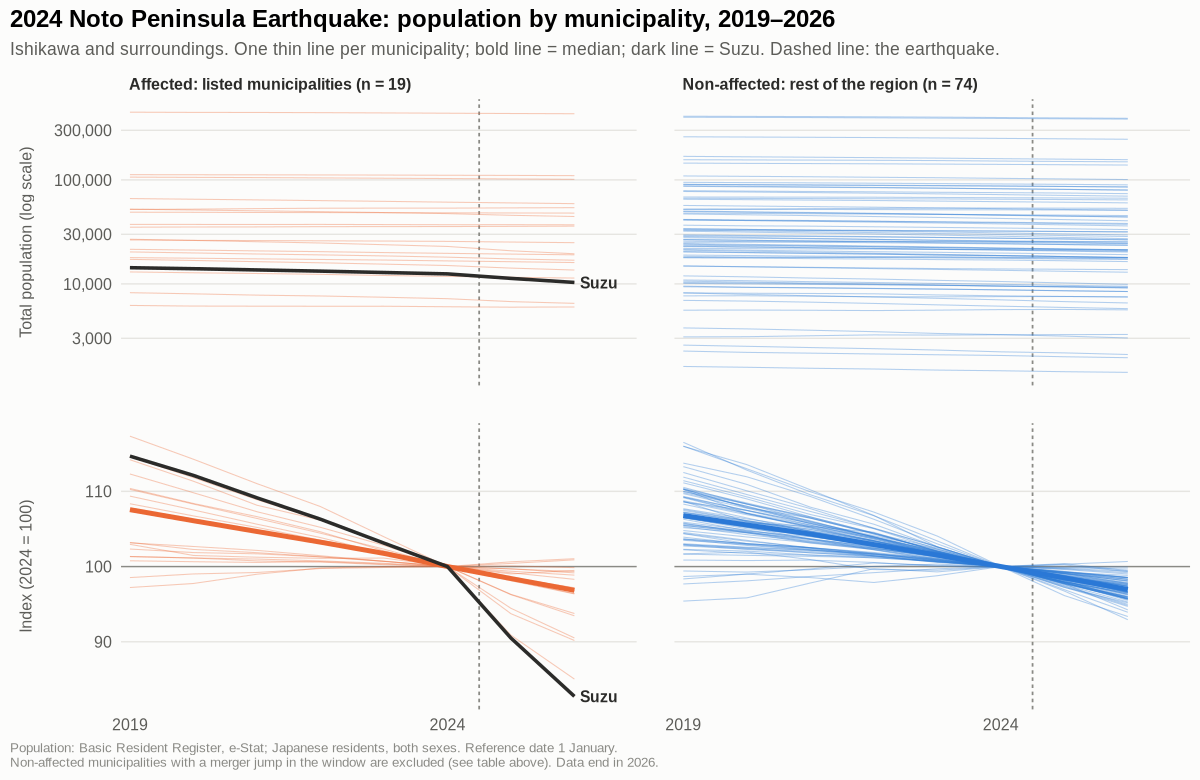

In [24]:
show_save(plot_trend("noto"), "12_trend_noto", width = 12, height = 9)